# EDA 03 — Primeira passagem pelo dataset SRAG

In [1]:
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from IPython.display import display


def encontrar_raiz_projeto() -> Path:
    pasta_atual = Path.cwd().resolve()

    for pasta in [pasta_atual, *pasta_atual.parents]:
        possui_src = (pasta / "src").is_dir()
        possui_configs = (pasta / "configs").is_dir()

        if possui_src and possui_configs:
            return pasta

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto."
    )


ROOT_DIR = encontrar_raiz_projeto()

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


from src import config as C
from src import config as env
from src import dados as storage


env.carregar_dotenv()

print(f"Raiz do projeto: {ROOT_DIR}")
print(f"Python: {sys.version.split()[0]}")
print(f"Sistema: {platform.system()} {platform.release()}")
print(f"pandas: {pd.__version__}")

Raiz do projeto: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador
Python: 3.14.8
Sistema: Windows 11
pandas: 3.0.6


In [2]:
print(C.resumo())

print(f"Release configurada: {C.DATA_VERSION}")
print(f"Nome do arquivo: {C.PARQUET_NAME}")
print(f"Diretório de tabelas: {C.TABLES_DIR}")
print(f"Diretório de figuras: {C.FIGURES_DIR}")

ROOT_DIR          = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador
DATA_DIR          = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\data
PROCESSED_DIR     = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\data\processed
ANALYTICAL_DIR    = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\data\analytical
OUTPUTS_DIR       = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs
RUNS_DIR          = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\runs
CONFIGS_DIR       = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\configs
SUPERVISED_YAML   = C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\configs\supervised.yaml (ok)
PARQUET_NAME      = srag.parquet
DATA_VERSION      = dados-v2
GITHUB_REPO       = Ivan-S-Oliveira/Projeto_Integrador
HTTP_TIMEOUT      = 180
HTTP_TENTATIVAS   = 3
SEED              = 42
GITHUB_TOKEN?     = False
SRAG_PARQUET_URL  = https://gi

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns


COR_PADRAO = "tab:blue"
COR_VALIDA = "tab:green"
COR_ATENCAO = "tab:orange"
COR_PROBLEMA = "tab:red"
COR_AUSENTE = "tab:gray"

CORES_GRUPOS_EDA = {
    "Estrutura": "tab:blue",
    "Candidatas principais": "tab:green",
    "Textos complementares": "tab:gray",
    "Geografia": "tab:purple",
    "Vacinação condicional": "tab:orange",
    "Contexto social": "tab:brown",
    "Tratamento e auditoria": "tab:cyan",
    "Desfecho e auditoria": "tab:red",
}

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["legend.fontsize"] = 9
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9

print("Configuração visual do Notebook 03 carregada.")

Configuração visual do Notebook 03 carregada.


In [4]:
COLUNAS_ESTRUTURA = [
    "nu_notific",
    "dt_notific",
    "dt_sin_pri",
    "sem_pri",
    "hospital",
    "dt_interna",
]

COLUNAS_CANDIDATAS_PRINCIPAIS = [
    "cs_sexo",
    "nu_idade_n",
    "tp_idade",
    "cs_gestant",
    "cs_raca",
    "cs_etinia",
    "cs_escol_n",
    "cs_zona",
    "ave_suino",
    "out_anim",
    "febre",
    "tosse",
    "garganta",
    "dispneia",
    "desc_resp",
    "saturacao",
    "diarreia",
    "vomito",
    "dor_abd",
    "fadiga",
    "perd_olft",
    "perd_pala",
    "puerpera",
    "cardiopati",
    "hematologi",
    "sind_down",
    "hepatica",
    "asma",
    "diabetes",
    "neurologic",
    "pneumopati",
    "imunodepre",
    "renal",
    "obesidade",
    "tabag",
]

COLUNAS_COMPLEMENTARES_TEXTO = [
    "outro_sin",
    "outro_des",
    "obes_imc",
    "out_morbi",
    "morb_desc",
    "out_antiv",
    "out_trat",
]

COLUNAS_GEOGRAFIA = [
    "sg_uf_not",
    "co_regiona",
    "co_mun_not",
    "co_pais",
    "sg_uf",
    "co_rg_resi",
    "co_mun_res",
    "sg_uf_inte",
    "co_rg_inte",
    "co_mu_inte",
]

COLUNAS_CONDICIONAIS_VACINACAO = [
    "vacina",
    "dt_ut_dose",
    "mae_vac",
    "dt_vac_mae",
    "m_amamenta",
    "dt_doseuni",
    "dt_1_dose",
    "dt_2_dose",
    "vacina_cov",
    "dose_1_cov",
    "dose_2_cov",
    "dose_ref",
    "dose_2ref",
    "dose_adic",
    "dos_re_bi",
]

COLUNAS_CONTEXTO_SOCIAL_CONDICIONAL = [
    "pac_cocbo",
    "pac_dscbo",
    "pov_ct",
    "tp_pov_ct",
    "estrang",
]

COLUNAS_TRATAMENTO_AUDITORIA = [
    "antiviral",
    "tp_antivir",
    "dt_antivir",
    "trat_cov",
    "tipo_trat",
    "dt_trt_cov",
]

COLUNAS_DESFECHO_AUDITORIA = [
    "evolucao",
    "dt_evoluca",
    "dt_encerra",
    "dt_digita",
]

COLUNAS_EDA = list(
    dict.fromkeys(
        COLUNAS_ESTRUTURA
        + COLUNAS_CANDIDATAS_PRINCIPAIS
        + COLUNAS_COMPLEMENTARES_TEXTO
        + COLUNAS_GEOGRAFIA
        + COLUNAS_CONDICIONAIS_VACINACAO
        + COLUNAS_CONTEXTO_SOCIAL_CONDICIONAL
        + COLUNAS_TRATAMENTO_AUDITORIA
        + COLUNAS_DESFECHO_AUDITORIA
    )
)

ANO_INICIAL_COORTE = 2019
ANO_FINAL_COORTE = 2026

ANOS_COORTE = list(
    range(
        ANO_INICIAL_COORTE,
        ANO_FINAL_COORTE + 1,
    )
)

print(
    "Período definido para a coorte:",
    f"{ANO_INICIAL_COORTE}-{ANO_FINAL_COORTE}",
)

print(f"Total de colunas da EDA: {len(COLUNAS_EDA)}")
print(f"Colunas de estrutura: {len(COLUNAS_ESTRUTURA)}")
print(f"Colunas candidatas: {len(COLUNAS_CANDIDATAS_PRINCIPAIS)}")
print(f"Colunas complementares de texto: {len(COLUNAS_COMPLEMENTARES_TEXTO)}")
print(f"Colunas geográficas: {len(COLUNAS_GEOGRAFIA)}")
print(f"Colunas Condicionais de Vacinação: {len(COLUNAS_CONDICIONAIS_VACINACAO)}")
print(f"Colunas Contexto Social: {len(COLUNAS_CONTEXTO_SOCIAL_CONDICIONAL)}")
print(f"Colunas de auditoria: {len(COLUNAS_TRATAMENTO_AUDITORIA)}")
print(f"Colunas de Desfecho: {len(COLUNAS_DESFECHO_AUDITORIA)}")
print(f"Total sem duplicidades: {len(COLUNAS_EDA)}")

Período definido para a coorte: 2019-2026
Total de colunas da EDA: 88
Colunas de estrutura: 6
Colunas candidatas: 35
Colunas complementares de texto: 7
Colunas geográficas: 10
Colunas Condicionais de Vacinação: 15
Colunas Contexto Social: 5
Colunas de auditoria: 6
Colunas de Desfecho: 4
Total sem duplicidades: 88


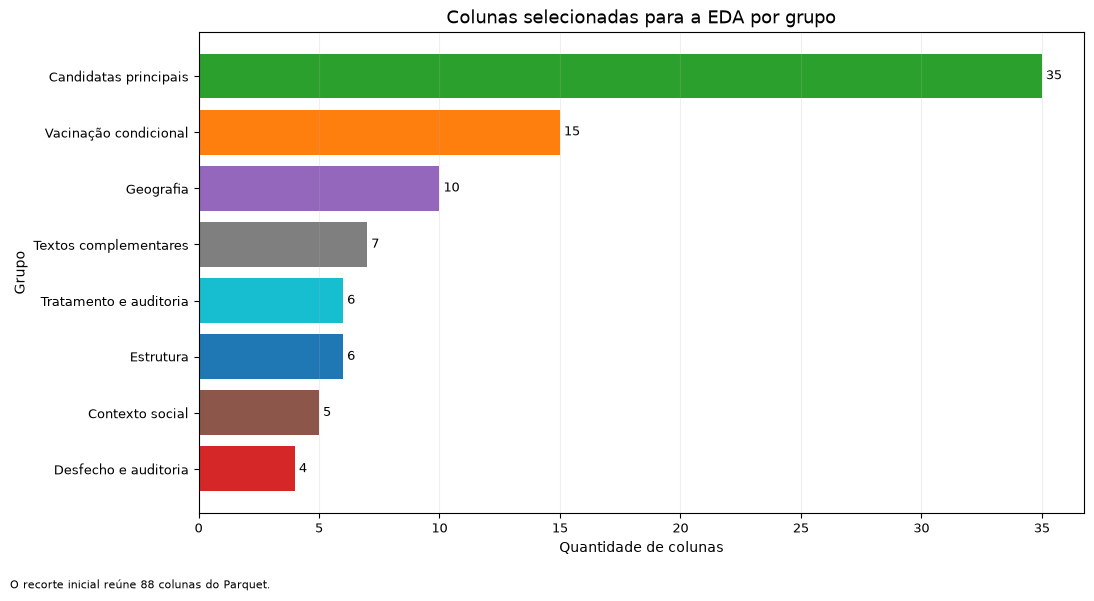

,grupo,quantidade_colunas
0,Candidatas principais,35
1,Vacinação condicional,15
2,Geografia,10
3,Textos complementares,7
4,Estrutura,6
5,Tratamento e auditoria,6
6,Contexto social,5
7,Desfecho e auditoria,4


In [5]:
quantidade_colunas_por_grupo = pd.DataFrame(
    {
        "grupo": [
            "Estrutura",
            "Candidatas principais",
            "Textos complementares",
            "Geografia",
            "Vacinação condicional",
            "Contexto social",
            "Tratamento e auditoria",
            "Desfecho e auditoria",
        ],
        "quantidade_colunas": [
            len(COLUNAS_ESTRUTURA),
            len(COLUNAS_CANDIDATAS_PRINCIPAIS),
            len(COLUNAS_COMPLEMENTARES_TEXTO),
            len(COLUNAS_GEOGRAFIA),
            len(COLUNAS_CONDICIONAIS_VACINACAO),
            len(COLUNAS_CONTEXTO_SOCIAL_CONDICIONAL),
            len(COLUNAS_TRATAMENTO_AUDITORIA),
            len(COLUNAS_DESFECHO_AUDITORIA),
        ],
    }
)

quantidade_colunas_por_grupo = (
    quantidade_colunas_por_grupo
    .sort_values("quantidade_colunas", ascending=True)
    .reset_index(drop=True)
)

total_colunas_grupos = int(
    quantidade_colunas_por_grupo["quantidade_colunas"].sum()
)

if total_colunas_grupos != len(COLUNAS_EDA):
    raise RuntimeError(
        "A soma das colunas por grupo não corresponde "
        "ao total de colunas da EDA."
    )

cores_colunas_grupo = [
    CORES_GRUPOS_EDA[grupo]
    for grupo in quantidade_colunas_por_grupo["grupo"]
]

figura_colunas_grupo, eixo_colunas_grupo = plt.subplots(figsize=(11, 6))

barras_colunas_grupo = eixo_colunas_grupo.barh(
    quantidade_colunas_por_grupo["grupo"],
    quantidade_colunas_por_grupo["quantidade_colunas"],
    color=cores_colunas_grupo,
)

eixo_colunas_grupo.set_title("Colunas selecionadas para a EDA por grupo")
eixo_colunas_grupo.set_xlabel("Quantidade de colunas")
eixo_colunas_grupo.set_ylabel("Grupo")
eixo_colunas_grupo.set_xlim(left=0)
eixo_colunas_grupo.grid(axis="x", alpha=0.20)

for barra, quantidade in zip(
    barras_colunas_grupo,
    quantidade_colunas_por_grupo["quantidade_colunas"],
):
    eixo_colunas_grupo.text(
        barra.get_width(),
        barra.get_y() + barra.get_height() / 2,
        f" {int(quantidade)}",
        ha="left",
        va="center",
        fontsize=9,
    )

figura_colunas_grupo.text(
    0.01,
    0.01,
    f"O recorte inicial reúne {len(COLUNAS_EDA)} colunas do Parquet.",
    fontsize=8,
)

figura_colunas_grupo.tight_layout(rect=(0, 0.04, 1, 1))

plt.show()
plt.close(figura_colunas_grupo)

display(
    quantidade_colunas_por_grupo
    .sort_values("quantidade_colunas", ascending=False)
    .reset_index(drop=True)
)

In [6]:
caminho_parquet = storage.get_parquet(force=False)

print(f"Arquivo: {caminho_parquet}")
print(f"Existe: {caminho_parquet.exists()}")
print(
    "Tamanho do arquivo: "
    f"{caminho_parquet.stat().st_size / 1024**2:,.2f} MB, "
    f"{caminho_parquet.stat().st_size:,.2f} bytes"
)

Arquivo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\data\processed\dados-v2\srag.parquet
Existe: True
Tamanho do arquivo: 289.51 MB, 303,573,013.00 bytes


In [7]:
arquivo_parquet = pq.ParquetFile(caminho_parquet)

schema = arquivo_parquet.schema_arrow
colunas_disponiveis = schema.names

metadados_parquet = {
    "arquivo": caminho_parquet.name,
    "versao_dados": C.DATA_VERSION,
    "numero_linhas": arquivo_parquet.metadata.num_rows,
    "numero_colunas": arquivo_parquet.metadata.num_columns,
    "numero_row_groups": arquivo_parquet.metadata.num_row_groups,
}

display(pd.DataFrame([metadados_parquet]))

,arquivo,versao_dados,numero_linhas,numero_colunas,numero_row_groups
0,srag.parquet,dados-v2,4666910,198,28


In [8]:
schema_df = pd.DataFrame(
    {
        "coluna": schema.names,
        "tipo_arrow": [str(campo.type) for campo in schema],
    }
)

display(schema_df.head(20))
print(f"Total de campos no schema: {len(schema_df)}")

,coluna,tipo_arrow
0,id_registro,int64
1,ano_arquivo,int16
2,data_snapshot,date32[day]
3,arquivo_origem,string
4,nu_notific,string
5,dt_notific,string
6,sem_not,string
7,dt_sin_pri,string
8,sem_pri,string
9,sg_uf_not,string


Total de campos no schema: 198


In [9]:
conjunto_colunas_disponiveis = set(colunas_disponiveis)

status_colunas = pd.DataFrame(
    {
        "coluna": COLUNAS_EDA,
        "grupo": (
            ["estrutura"] * len(COLUNAS_ESTRUTURA)
            + ["candidatas_principais"] * len(COLUNAS_CANDIDATAS_PRINCIPAIS)
            + ["complementares_texto"] * len(COLUNAS_COMPLEMENTARES_TEXTO)
            + ["geografia"] * len(COLUNAS_GEOGRAFIA)
            + ["condicionais_vacinacao"] * len(COLUNAS_CONDICIONAIS_VACINACAO)
            + ["contexto_social_condicional"] * len(COLUNAS_CONTEXTO_SOCIAL_CONDICIONAL)
            + ["tratamento_auditoria"] * len(COLUNAS_TRATAMENTO_AUDITORIA)
            + ["desfecho_auditoria"] * len(COLUNAS_DESFECHO_AUDITORIA)
        ),
    }
)

status_colunas["existe_no_parquet"] = status_colunas["coluna"].isin(conjunto_colunas_disponiveis)

display(status_colunas)

colunas_ausentes = status_colunas.loc[
    ~status_colunas["existe_no_parquet"], "coluna"
].tolist()

if colunas_ausentes:
    print("Colunas ausentes:")
    for coluna in colunas_ausentes:
        print(f"- {coluna}")
else:
    print("Todas as colunas solicitadas existem no Parquet.")

,coluna,grupo,existe_no_parquet
0,nu_notific,estrutura,True
1,dt_notific,estrutura,True
2,dt_sin_pri,estrutura,True
3,sem_pri,estrutura,True
4,hospital,estrutura,True
...,...,...,...
83,dt_trt_cov,tratamento_auditoria,True
84,evolucao,desfecho_auditoria,True
85,dt_evoluca,desfecho_auditoria,True
86,dt_encerra,desfecho_auditoria,True


Todas as colunas solicitadas existem no Parquet.


In [10]:
df = storage.read_srag(
    columns=COLUNAS_EDA,
    compactar=True,
    colunas_texto_livre=COLUNAS_COMPLEMENTARES_TEXTO,
)

print(f"Linhas carregadas: {df.shape[0]:,}")
print(f"Colunas carregadas: {df.shape[1]:,}")

display(df.head(0))

Linhas carregadas: 4,666,910
Colunas carregadas: 88


,nu_notific,dt_notific,dt_sin_pri,sem_pri,hospital,dt_interna,cs_sexo,nu_idade_n,tp_idade,cs_gestant,...,antiviral,tp_antivir,dt_antivir,trat_cov,tipo_trat,dt_trt_cov,evolucao,dt_evoluca,dt_encerra,dt_digita


In [11]:
tipos_memoria = pd.DataFrame(
    {
        "coluna": df.columns,
        "tipo_pandas": [str(df[c].dtype) for c in df.columns],
        "memoria_mb": [df[c].memory_usage(deep=True) / 1024**2 for c in df.columns],
    }
).sort_values("memoria_mb", ascending=False).reset_index(drop=True)

memoria_total_mb = df.memory_usage(deep=True).sum() / 1024**2

print(f"Memória total: {memoria_total_mb:,.2f} MB")
display(tipos_memoria)

Memória total: 1,021.28 MB


,coluna,tipo_pandas,memoria_mb
0,nu_notific,category,239.078484
1,outro_des,string,55.452329
2,morb_desc,string,48.541237
3,outro_sin,string,39.342866
4,out_morbi,string,37.990662
...,...,...,...
83,fadiga,category,4.450864
84,vacina_cov,category,4.450864
85,estrang,category,4.450855
86,pov_ct,category,4.450855


In [12]:
print(f"Memória total utilizada: {memoria_total_mb:,.2f} MB")

Memória total utilizada: 1,021.28 MB


In [13]:
display(tipos_memoria)

,coluna,tipo_pandas,memoria_mb
0,nu_notific,category,239.078484
1,outro_des,string,55.452329
2,morb_desc,string,48.541237
3,outro_sin,string,39.342866
4,out_morbi,string,37.990662
...,...,...,...
83,fadiga,category,4.450864
84,vacina_cov,category,4.450864
85,estrang,category,4.450855
86,pov_ct,category,4.450855


In [14]:
ausencias = pd.DataFrame(
    {
        "coluna": df.columns,
        "quantidade_ausente": [df[c].isna().sum() for c in df.columns],
        "quantidade_preenchida": [df[c].notna().sum() for c in df.columns],
    }
)

ausencias["percentual_ausente"] = ausencias["quantidade_ausente"] / len(df) * 100
ausencias["percentual_preenchido"] = ausencias["quantidade_preenchida"] / len(df) * 100

ausencias = ausencias.sort_values("percentual_ausente", ascending=False).reset_index(drop=True)

display(ausencias)

,coluna,quantidade_ausente,quantidade_preenchida,percentual_ausente,percentual_preenchido
0,tabag,4666910,0,100.000000,0.000000
1,out_trat,4664116,2794,99.940132,0.059868
2,dt_trt_cov,4663077,3833,99.917869,0.082131
3,tipo_trat,4662126,4784,99.897491,0.102509
4,out_anim,4661634,5276,99.886949,0.113051
...,...,...,...,...,...
83,dt_notific,0,4666910,0.000000,100.000000
84,sem_pri,0,4666910,0.000000,100.000000
85,dt_sin_pri,0,4666910,0.000000,100.000000
86,cs_sexo,0,4666910,0.000000,100.000000


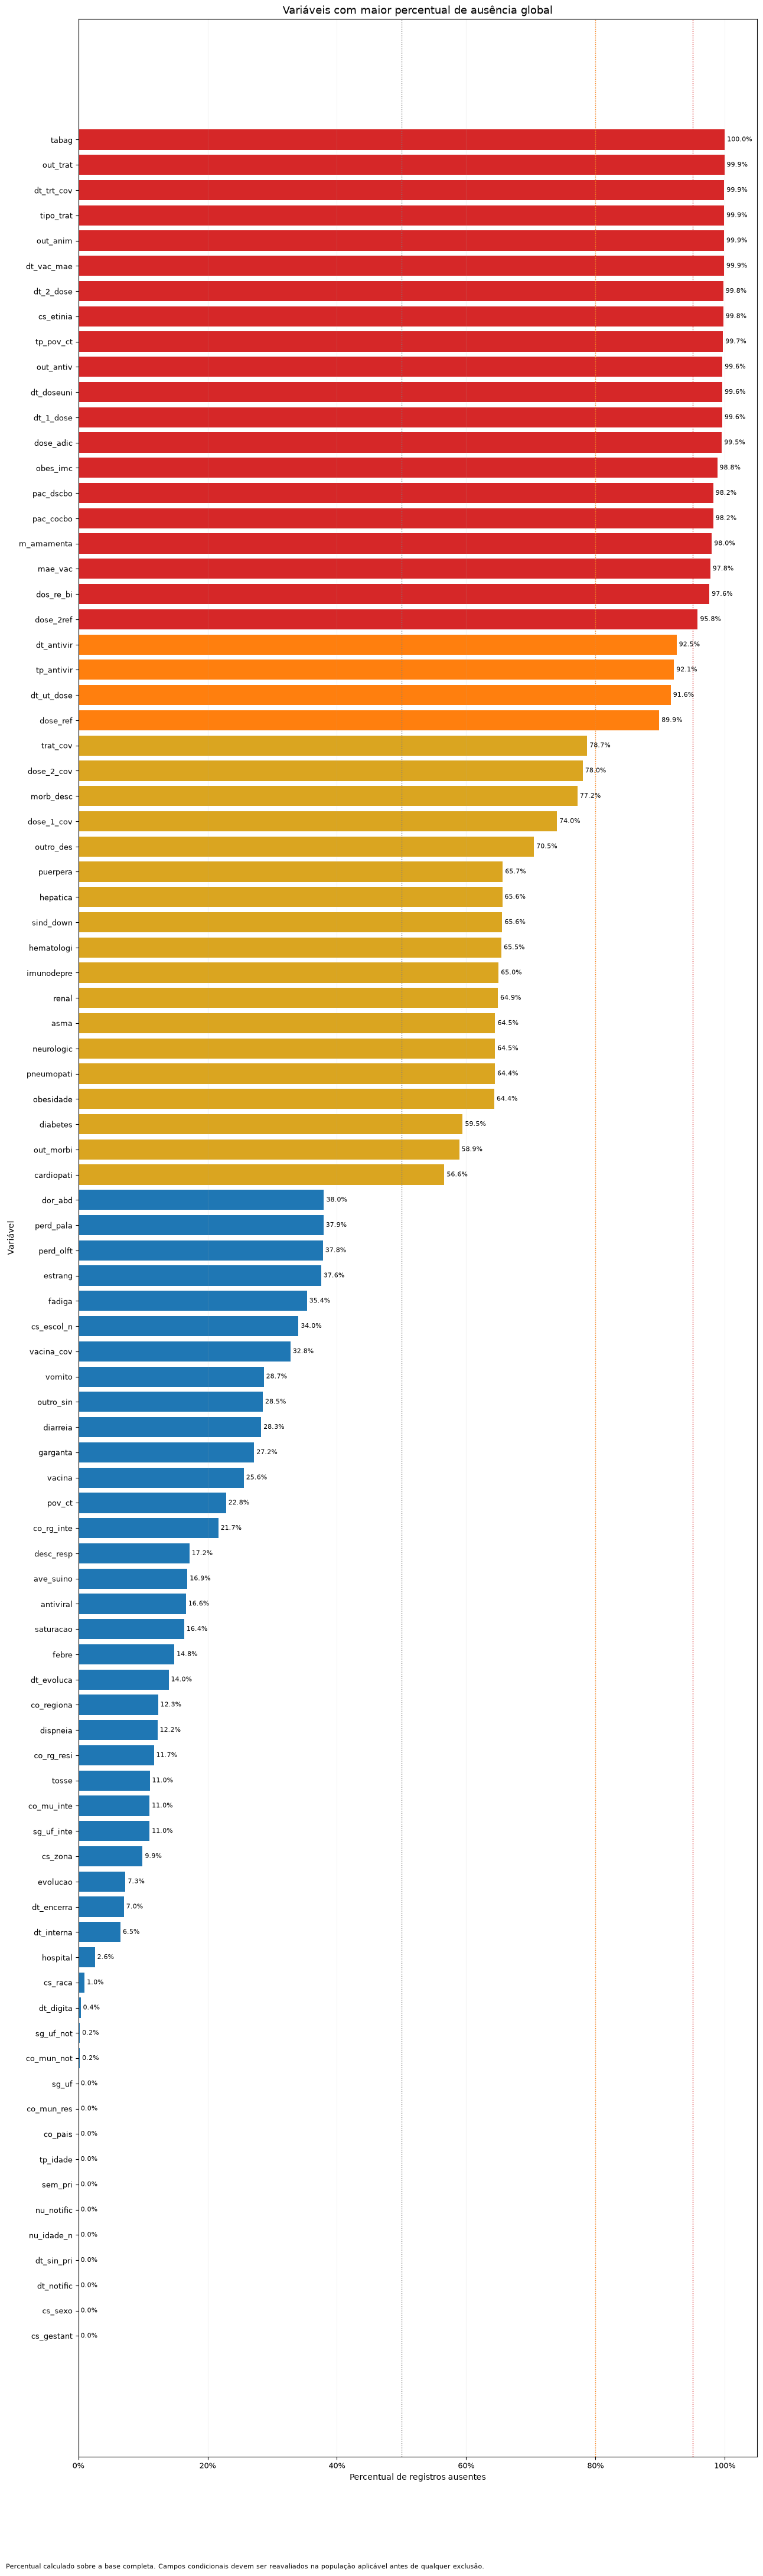

,coluna,quantidade_ausente,quantidade_preenchida,percentual_ausente,percentual_preenchido,grupo
0,tabag,4666910,0,100.000000,0.000000,candidatas_principais
1,out_trat,4664116,2794,99.940132,0.059868,complementares_texto
2,dt_trt_cov,4663077,3833,99.917869,0.082131,tratamento_auditoria
3,tipo_trat,4662126,4784,99.897491,0.102509,tratamento_auditoria
4,out_anim,4661634,5276,99.886949,0.113051,candidatas_principais
...,...,...,...,...,...,...
83,dt_sin_pri,0,4666910,0.000000,100.000000,estrutura
84,nu_idade_n,0,4666910,0.000000,100.000000,candidatas_principais
85,nu_notific,0,4666910,0.000000,100.000000,estrutura
86,sem_pri,0,4666910,0.000000,100.000000,estrutura


In [15]:
from matplotlib.ticker import PercentFormatter

QUANTIDADE_VARIAVEIS_AUSENCIA_GRAFICO = 100

ranking_ausencia = ausencias[
    ["coluna", "quantidade_ausente", "quantidade_preenchida", "percentual_ausente", "percentual_preenchido"]
].copy()

if "status_colunas" in globals():
    ranking_ausencia = ranking_ausencia.merge(
        status_colunas[["coluna", "grupo"]],
        on="coluna", how="left", validate="one_to_one",
    )

if "grupo" not in ranking_ausencia.columns:
    ranking_ausencia["grupo"] = "grupo_nao_informado"

ranking_ausencia["percentual_ausente"] = pd.to_numeric(
    ranking_ausencia["percentual_ausente"], errors="coerce"
)

ranking_ausencia = (
    ranking_ausencia.dropna(subset=["percentual_ausente"])
    .sort_values(["percentual_ausente", "coluna"], ascending=[False, True])
    .head(QUANTIDADE_VARIAVEIS_AUSENCIA_GRAFICO)
    .sort_values("percentual_ausente", ascending=True)
    .reset_index(drop=True)
)

def definir_cor_ausencia(percentual: float) -> str:
    if percentual >= 95:
        return "tab:red"
    if percentual >= 80:
        return "tab:orange"
    if percentual >= 50:
        return "goldenrod"
    return "tab:blue"

cores_ausencia = [definir_cor_ausencia(p) for p in ranking_ausencia["percentual_ausente"]]

altura_figura = max(8, len(ranking_ausencia) / 2)

figura_ausencia, eixo_ausencia = plt.subplots(figsize=(13, altura_figura))

barras_ausencia = eixo_ausencia.barh(
    ranking_ausencia["coluna"],
    ranking_ausencia["percentual_ausente"],
    color=cores_ausencia,
)

eixo_ausencia.set_title("Variáveis com maior percentual de ausência global")
eixo_ausencia.set_xlabel("Percentual de registros ausentes")
eixo_ausencia.set_ylabel("Variável")
eixo_ausencia.set_xlim(0, 105)
eixo_ausencia.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
eixo_ausencia.axvline(x=50, color="tab:gray", linestyle=":", linewidth=1)
eixo_ausencia.axvline(x=80, color="tab:orange", linestyle=":", linewidth=1)
eixo_ausencia.axvline(x=95, color="tab:red", linestyle=":", linewidth=1)
eixo_ausencia.grid(axis="x", alpha=0.15)

for barra, percentual in zip(barras_ausencia, ranking_ausencia["percentual_ausente"]):
    eixo_ausencia.text(
        barra.get_width(),
        barra.get_y() + barra.get_height() / 2,
        f" {percentual:.1f}%",
        ha="left", va="center", fontsize=8,
    )

figura_ausencia.text(
    0.01, 0.01,
    "Percentual calculado sobre a base completa. Campos condicionais devem "
    "ser reavaliados na população aplicável antes de qualquer exclusão.",
    fontsize=8,
)

figura_ausencia.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
plt.close(figura_ausencia)

display(
    ranking_ausencia.sort_values(
        ["percentual_ausente", "coluna"], ascending=[False, True]
    ).reset_index(drop=True)
)

In [16]:
import gc

try:
    from src.features import parse_srag_date  # type: ignore[reportAttributeAccessIssue]
except ImportError:
    def parse_srag_date(serie):
        resultado = pd.to_datetime(serie, errors="coerce")
        mascara = resultado.isna() & serie.notna()
        if mascara.any():
            resultado = resultado.fillna(
                pd.to_datetime(serie, errors="coerce", format="%d/%m/%Y")
            )
        return resultado


ano_notificacao = parse_srag_date(df["dt_notific"]).dt.year
ano_internacao = parse_srag_date(df["dt_interna"]).dt.year

TAMANHO_LOTE_COLUNAS_PREENCHIMENTO = 5


def calcular_preenchimento_por_grupo(
    dados, serie_grupo, colunas, nome_grupo, tamanho_lote=5,
):
    if len(dados) != len(serie_grupo):
        raise ValueError("A base e a série de agrupamento diferem em tamanho.")
    if tamanho_lote <= 0:
        raise ValueError("O tamanho do lote precisa ser maior que zero.")

    colunas_disponiveis = [c for c in colunas if c in dados.columns]
    if not colunas_disponiveis:
        raise ValueError("Nenhuma coluna de COLUNAS_EDA está disponível.")

    serie_grupo_alinhada = pd.Series(serie_grupo, index=dados.index, name=nome_grupo)

    quantidade_por_grupo = (
        serie_grupo_alinhada
        .groupby(serie_grupo_alinhada, dropna=True, observed=True, sort=True)
        .size()
        .rename("quantidade_registros")
    )

    resultados_lotes = []

    for inicio in range(0, len(colunas_disponiveis), tamanho_lote):
        fim = min(inicio + tamanho_lote, len(colunas_disponiveis))
        colunas_lote = colunas_disponiveis[inicio:fim]

        contagem_preenchida = (
            dados[colunas_lote]
            .groupby(serie_grupo_alinhada, dropna=True, observed=True, sort=True)
            .count()
        )

        percentual_preenchido = (
            contagem_preenchida.div(quantidade_por_grupo, axis=0).mul(100)
        )

        resultados_lotes.append(percentual_preenchido)
        del contagem_preenchida, percentual_preenchido
        gc.collect()

    resultado = (
        pd.concat(resultados_lotes, axis=1)
        .reindex(columns=colunas_disponiveis)
        .rename_axis(nome_grupo)
        .reset_index()
    )

    if not resultado[colunas_disponiveis].stack().between(0, 100, inclusive="both").all():
        raise RuntimeError("Percentuais fora do intervalo 0–100%.")

    del resultados_lotes, quantidade_por_grupo, serie_grupo_alinhada
    gc.collect()

    return resultado


ano_notificacao_calculo = pd.to_numeric(ano_notificacao, errors="coerce").astype("Int16")

preenchimento_por_ano_notificacao = calcular_preenchimento_por_grupo(
    dados=df,
    serie_grupo=ano_notificacao_calculo,
    colunas=COLUNAS_EDA,
    nome_grupo="ano_notificacao",
    tamanho_lote=TAMANHO_LOTE_COLUNAS_PREENCHIMENTO,
)

display(preenchimento_por_ano_notificacao.head(20))

ano_internacao_calculo = pd.to_numeric(ano_internacao, errors="coerce").astype("Int16")

ano_internacao_estudo = ano_internacao_calculo.where(
    ano_internacao_calculo.between(
        ANO_INICIAL_COORTE, ANO_FINAL_COORTE, inclusive="both"
    )
)

preenchimento_por_ano_internacao = calcular_preenchimento_por_grupo(
    dados=df,
    serie_grupo=ano_internacao_estudo,
    colunas=COLUNAS_EDA,
    nome_grupo="ano_internacao",
    tamanho_lote=TAMANHO_LOTE_COLUNAS_PREENCHIMENTO,
)

display(preenchimento_por_ano_internacao.head(20))

del ano_notificacao_calculo, ano_internacao_calculo, ano_internacao_estudo
gc.collect()

print("Cálculo temporal concluído.")

,ano_notificacao,nu_notific,dt_notific,dt_sin_pri,sem_pri,hospital,dt_interna,cs_sexo,nu_idade_n,tp_idade,...,antiviral,tp_antivir,dt_antivir,trat_cov,tipo_trat,dt_trt_cov,evolucao,dt_evoluca,dt_encerra,dt_digita
0,2018,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,66.666667,66.666667,0.0,0.0,0.0,100.0,100.0,100.0,66.666667
1,2019,100.0,100.0,100.0,100.0,99.44072,97.318748,100.0,100.0,100.0,...,98.603857,60.762018,60.759962,0.19328,0.0,0.0,94.18925,84.081096,96.418144,65.419254
2,2020,100.0,100.0,100.0,100.0,97.624625,92.570772,100.0,100.0,100.0,...,86.346381,14.819022,14.513047,1.013939,0.016278,0.000783,93.641206,87.272401,94.055643,100.0
3,2021,100.0,100.0,100.0,100.0,97.372476,93.659249,100.0,100.0,100.0,...,81.779043,2.246043,1.929223,1.078881,0.007329,0.002988,91.929025,85.798999,92.465534,100.0
4,2022,100.0,100.0,100.0,100.0,96.706461,92.862856,100.0,100.0,100.0,...,79.995915,3.612766,3.271742,16.454821,0.171456,0.140735,91.922335,85.642815,91.871018,100.0
5,2023,100.0,100.0,100.0,100.0,97.215023,94.232778,100.0,100.0,100.0,...,81.149365,5.872714,5.345256,74.884223,0.420208,0.318584,94.987745,88.1533,94.461694,100.0
6,2024,100.0,100.0,100.0,100.0,97.840749,94.319955,100.0,100.0,100.0,...,81.12871,8.117861,7.524235,75.597258,0.359379,0.320275,94.4179,87.878325,93.960949,100.0
7,2025,100.0,100.0,100.0,100.0,97.96091,94.575476,100.0,100.0,100.0,...,86.048833,11.776098,10.798542,79.988643,0.273453,0.249544,95.45172,86.436747,95.267326,100.0
8,2026,100.0,100.0,100.0,100.0,97.635766,93.910212,100.0,100.0,100.0,...,87.33915,12.552175,11.804758,81.069716,0.174323,0.15525,86.790453,77.364123,86.690649,100.0


,ano_internacao,nu_notific,dt_notific,dt_sin_pri,sem_pri,hospital,dt_interna,cs_sexo,nu_idade_n,tp_idade,...,antiviral,tp_antivir,dt_antivir,trat_cov,tipo_trat,dt_trt_cov,evolucao,dt_evoluca,dt_encerra,dt_digita
0,2019,100.0,100.0,100.0,100.0,99.995793,100.0,100.0,100.0,100.0,...,98.870544,61.236723,61.23462,0.201914,0.0,0.0,94.359028,84.612472,96.529604,65.518982
1,2020,100.0,100.0,100.0,100.0,99.998978,100.0,100.0,100.0,100.0,...,88.417234,15.679015,15.354779,1.060039,0.02592,0.000836,94.355777,88.829544,94.676298,100.0
2,2021,100.0,100.0,100.0,100.0,99.999759,100.0,100.0,100.0,100.0,...,84.119165,2.359789,2.031382,1.122847,0.007421,0.003137,92.924676,87.289504,93.480971,100.0
3,2022,100.0,100.0,100.0,100.0,99.999627,100.0,100.0,100.0,100.0,...,82.695963,3.71455,3.38273,17.762877,0.188199,0.156117,93.681629,87.734246,93.562069,100.0
4,2023,100.0,100.0,100.0,100.0,99.999247,100.0,100.0,100.0,100.0,...,83.231892,5.961885,5.49326,77.100624,0.392967,0.327849,95.591164,89.567548,95.104471,100.0
5,2024,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,82.613363,8.373624,7.773309,77.156852,0.362715,0.32522,95.083417,89.083819,94.635055,100.0
6,2025,100.0,100.0,100.0,100.0,99.999683,100.0,100.0,100.0,100.0,...,87.510456,12.115039,11.144872,81.539909,0.276602,0.254423,96.233081,88.193247,95.954895,100.0
7,2026,100.0,100.0,100.0,100.0,99.999525,100.0,100.0,100.0,100.0,...,89.203471,12.875526,12.130414,83.009723,0.170597,0.153965,87.909978,79.482318,87.85438,100.0


Cálculo temporal concluído.


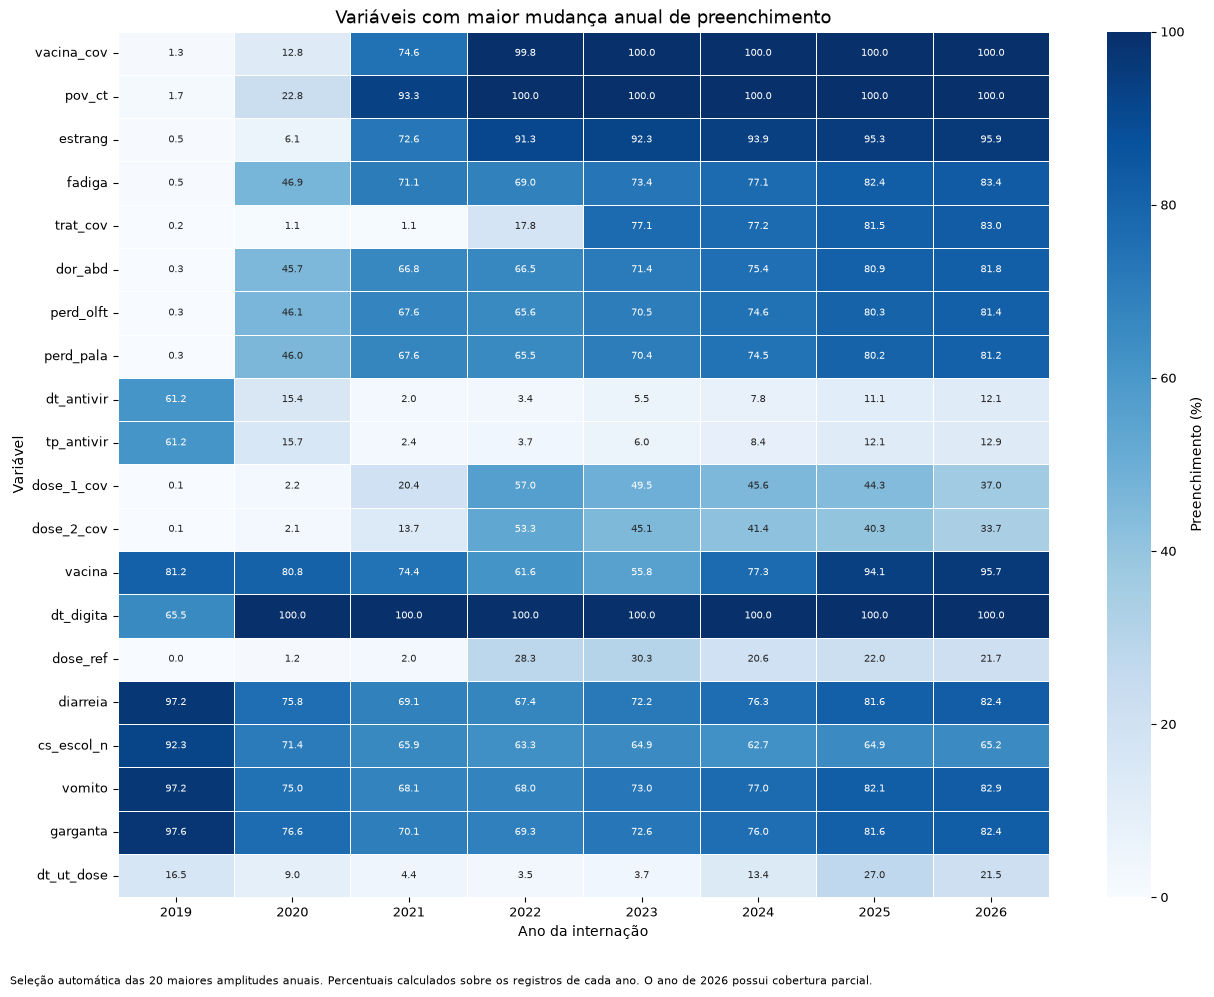

,coluna,amplitude_pontos_percentuais,quantidade_anos_observados
0,vacina_cov,98.677852,8
1,pov_ct,98.283731,8
2,estrang,95.397484,8
3,fadiga,82.867461,8
4,trat_cov,82.807809,8
5,dor_abd,81.518308,8
6,perd_olft,81.09531,8
7,perd_pala,80.911408,8
8,dt_antivir,59.203238,8
9,tp_antivir,58.876934,8


In [17]:
QUANTIDADE_VARIAVEIS_HEATMAP = 20
COLUNA_ANO_PREENCHIMENTO = "ano_internacao"

colunas_percentuais_preenchimento = (
    preenchimento_por_ano_internacao.columns
    .drop(COLUNA_ANO_PREENCHIMENTO)
    .tolist()
)

preenchimento_anual_matriz = (
    preenchimento_por_ano_internacao
    .set_index(COLUNA_ANO_PREENCHIMENTO)[colunas_percentuais_preenchimento]
    .apply(pd.to_numeric, errors="coerce")
    .sort_index()
)

preenchimento_anual_matriz.index = preenchimento_anual_matriz.index.astype(int)

amplitude_preenchimento = (
    preenchimento_anual_matriz.max(axis=0, skipna=True)
    .sub(preenchimento_anual_matriz.min(axis=0, skipna=True))
    .rename("amplitude_pontos_percentuais")
    .reset_index()
    .rename(columns={"index": "coluna"})
)

amplitude_preenchimento["quantidade_anos_observados"] = (
    amplitude_preenchimento["coluna"]
    .map(preenchimento_anual_matriz.notna().sum(axis=0))
    .astype("int64")
)

amplitude_preenchimento = (
    amplitude_preenchimento
    .sort_values(["amplitude_pontos_percentuais", "coluna"], ascending=[False, True])
    .reset_index(drop=True)
)

variaveis_maior_variacao = (
    amplitude_preenchimento
    .loc[amplitude_preenchimento["quantidade_anos_observados"].ge(2)]
    .head(QUANTIDADE_VARIAVEIS_HEATMAP)
    .copy()
)

colunas_heatmap_preenchimento = variaveis_maior_variacao["coluna"].tolist()

matriz_heatmap_preenchimento = (
    preenchimento_anual_matriz[colunas_heatmap_preenchimento]
    .transpose()
    .reindex(index=colunas_heatmap_preenchimento)
    .astype("float64")
)

figura_heatmap_preenchimento, eixo_heatmap_preenchimento = plt.subplots(figsize=(13, 10))

sns.heatmap(
    matriz_heatmap_preenchimento,
    annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Preenchimento (%)"},
    annot_kws={"fontsize": 7},
    ax=eixo_heatmap_preenchimento,
)

eixo_heatmap_preenchimento.set_title("Variáveis com maior mudança anual de preenchimento")
eixo_heatmap_preenchimento.set_xlabel("Ano da internação")
eixo_heatmap_preenchimento.set_ylabel("Variável")
eixo_heatmap_preenchimento.set_xticklabels(
    eixo_heatmap_preenchimento.get_xticklabels(), rotation=0,
)
eixo_heatmap_preenchimento.set_yticklabels(
    eixo_heatmap_preenchimento.get_yticklabels(), rotation=0,
)

figura_heatmap_preenchimento.text(
    0.01, 0.01,
    "Seleção automática das 20 maiores amplitudes anuais. Percentuais "
    "calculados sobre os registros de cada ano. O ano de 2026 possui "
    "cobertura parcial.",
    fontsize=8,
)

figura_heatmap_preenchimento.tight_layout(rect=(0.0, 0.04, 1.0, 1.0))
plt.show()
plt.close(figura_heatmap_preenchimento)

display(
    variaveis_maior_variacao[
        ["coluna", "amplitude_pontos_percentuais", "quantidade_anos_observados"]
    ].reset_index(drop=True)
)

In [18]:
cardinalidade_variaveis = pd.DataFrame(
    {
        "coluna": df.columns,
        "valores_distintos_sem_na": [df[c].nunique(dropna=True) for c in df.columns],
        "valores_distintos_com_na": [df[c].nunique(dropna=False) for c in df.columns],
    }
).sort_values("valores_distintos_com_na", ascending=False).reset_index(drop=True)

display(cardinalidade_variaveis)

,coluna,valores_distintos_sem_na,valores_distintos_com_na
0,nu_notific,4666881,4666881
1,outro_des,251506,251507
2,morb_desc,232631,232632
3,co_mun_res,5604,5605
4,co_mun_not,3661,3662
...,...,...,...
83,cs_sexo,3,3
84,tp_idade,3,3
85,estrang,2,3
86,pov_ct,2,3


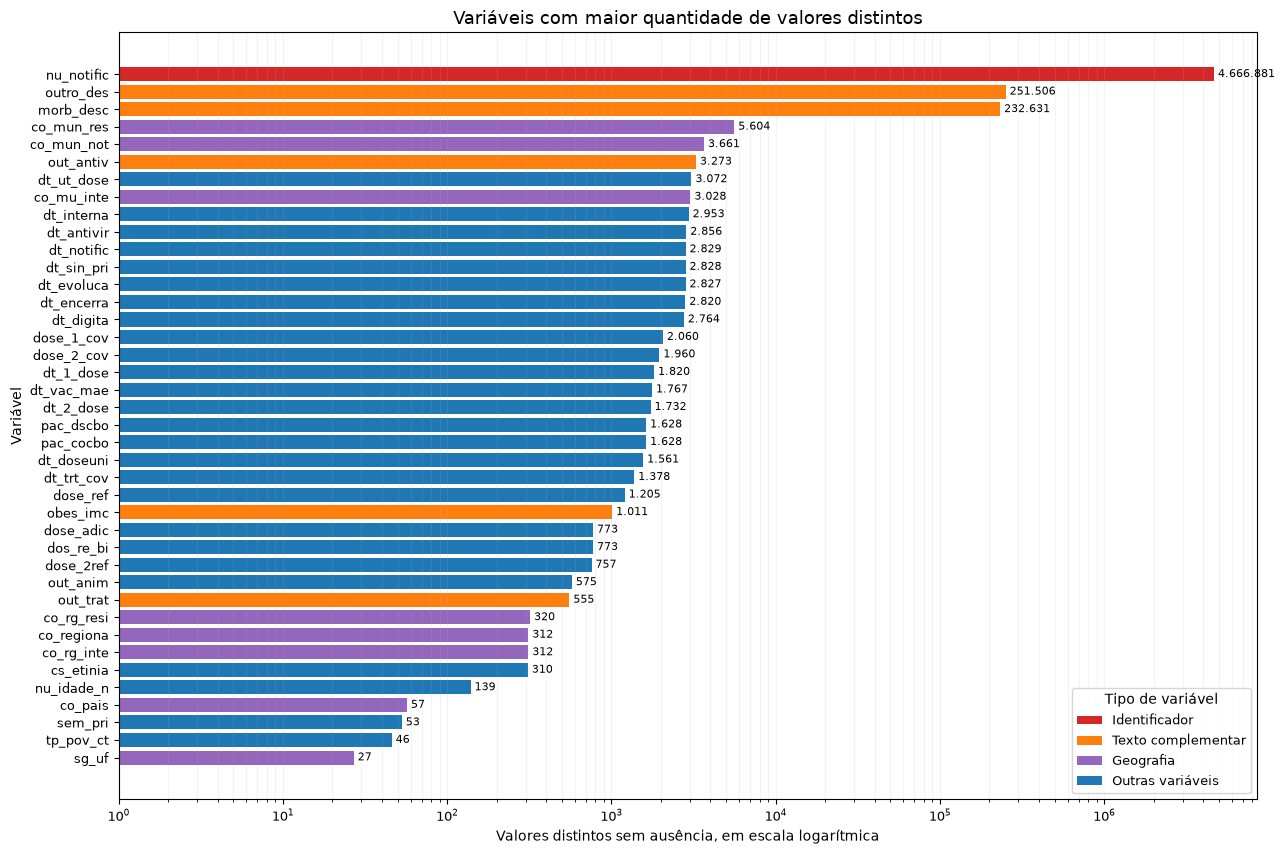

,coluna,valores_distintos_sem_na,valores_distintos_com_na
0,nu_notific,4666881,4666881
1,outro_des,251506,251507
2,morb_desc,232631,232632
3,co_mun_res,5604,5605
4,co_mun_not,3661,3662
5,out_antiv,3273,3274
6,dt_ut_dose,3072,3073
7,co_mu_inte,3028,3029
8,dt_interna,2953,2954
9,dt_antivir,2856,2857


In [19]:
from matplotlib.patches import Patch

QUANTIDADE_VARIAVEIS_CARDINALIDADE_GRAFICO = 40

ranking_cardinalidade = cardinalidade_variaveis[
    ["coluna", "valores_distintos_sem_na", "valores_distintos_com_na"]
].copy()

ranking_cardinalidade["valores_distintos_sem_na"] = pd.to_numeric(
    ranking_cardinalidade["valores_distintos_sem_na"], errors="coerce"
)
ranking_cardinalidade["valores_distintos_com_na"] = pd.to_numeric(
    ranking_cardinalidade["valores_distintos_com_na"], errors="coerce"
)

ranking_cardinalidade = (
    ranking_cardinalidade
    .dropna(subset=["valores_distintos_sem_na"])
    .loc[ranking_cardinalidade["valores_distintos_sem_na"].gt(0)]
    .sort_values(["valores_distintos_sem_na", "coluna"], ascending=[False, True])
    .head(QUANTIDADE_VARIAVEIS_CARDINALIDADE_GRAFICO)
    .sort_values("valores_distintos_sem_na", ascending=True)
    .reset_index(drop=True)
)

IDENTIFICADORES_CONHECIDOS = {"nu_notific"}
COLUNAS_TEXTO_LIVRE = set(COLUNAS_COMPLEMENTARES_TEXTO)
COLUNAS_GEOGRAFICAS = set(COLUNAS_GEOGRAFIA)

def definir_cor_cardinalidade(coluna: str) -> str:
    if coluna in IDENTIFICADORES_CONHECIDOS:
        return "tab:red"
    if coluna in COLUNAS_TEXTO_LIVRE:
        return "tab:orange"
    if coluna in COLUNAS_GEOGRAFICAS:
        return "tab:purple"
    return "tab:blue"

cores_cardinalidade = [
    definir_cor_cardinalidade(c) for c in ranking_cardinalidade["coluna"]
]

figura_cardinalidade, eixo_cardinalidade = plt.subplots(figsize=(13, 9))

barras_cardinalidade = eixo_cardinalidade.barh(
    ranking_cardinalidade["coluna"],
    ranking_cardinalidade["valores_distintos_sem_na"],
    color=cores_cardinalidade,
)

eixo_cardinalidade.set_title("Variáveis com maior quantidade de valores distintos")
eixo_cardinalidade.set_xlabel("Valores distintos sem ausência, em escala logarítmica")
eixo_cardinalidade.set_ylabel("Variável")
eixo_cardinalidade.set_xscale("log")
eixo_cardinalidade.set_xlim(left=1)
eixo_cardinalidade.grid(axis="x", which="both", alpha=0.15)

for barra, quantidade in zip(barras_cardinalidade, ranking_cardinalidade["valores_distintos_sem_na"]):
    eixo_cardinalidade.text(
        barra.get_width(),
        barra.get_y() + barra.get_height() / 2,
        f" {int(quantidade):,}".replace(",", "."),
        ha="left", va="center", fontsize=8,
    )

eixo_cardinalidade.legend(
    handles=[
        Patch(facecolor="tab:red", label="Identificador"),
        Patch(facecolor="tab:orange", label="Texto complementar"),
        Patch(facecolor="tab:purple", label="Geografia"),
        Patch(facecolor="tab:blue", label="Outras variáveis"),
    ],
    title="Tipo de variável",
    loc="lower right",
)

figura_cardinalidade.tight_layout(rect=(0.0, 0.04, 1.0, 1.0))
plt.show()
plt.close(figura_cardinalidade)

display(
    ranking_cardinalidade
    .sort_values(["valores_distintos_sem_na", "coluna"], ascending=[False, True])
    .reset_index(drop=True)
)

In [20]:
LIMITE_CARDINALIDADE = 30

colunas_categoricas_baixas = cardinalidade_variaveis.loc[
    cardinalidade_variaveis["valores_distintos_com_na"] <= LIMITE_CARDINALIDADE,
    "coluna",
].tolist()

frequencias_categoricas = []

for coluna in colunas_categoricas_baixas:
    frequencia = (
        df[coluna]
        .value_counts(dropna=False)
        .rename_axis("valor")
        .reset_index(name="quantidade")
    )
    frequencia.insert(0, "coluna", coluna)
    frequencia["percentual"] = frequencia["quantidade"] / len(df) * 100
    frequencias_categoricas.append(frequencia)

frequencias_categoricas_df = pd.concat(frequencias_categoricas, ignore_index=True)

display(frequencias_categoricas_df.head(100))

,coluna,valor,quantidade,percentual
0,sg_uf_not,SP,1306611,27.997347
1,sg_uf_not,MG,521998,11.185088
2,sg_uf_not,RJ,385820,8.26714
3,sg_uf_not,PR,380639,8.156125
4,sg_uf_not,RS,256895,5.504606
...,...,...,...,...
95,cs_escol_n,3,382584,8.197801
96,cs_escol_n,5,337951,7.24143
97,cs_escol_n,2,250435,5.366184
98,cs_escol_n,0,213463,4.573969


In [21]:
if "nu_notific" in df.columns:
    identificadores_preenchidos = df["nu_notific"].notna().sum()
    identificadores_duplicados = (
        df.loc[df["nu_notific"].notna(), "nu_notific"]
        .duplicated(keep=False)
        .sum()
    )

    resumo_identificador = pd.DataFrame(
        {
            "metrica": [
                "linhas_totais",
                "identificadores_preenchidos",
                "linhas_com_identificador_duplicado",
            ],
            "valor": [len(df), identificadores_preenchidos, identificadores_duplicados],
        }
    )

    display(resumo_identificador)

,metrica,valor
0,linhas_totais,4666910
1,identificadores_preenchidos,4666910
2,linhas_com_identificador_duplicado,58


In [22]:
REGRAS_AUDITORIA_TEMPORAL = [
    {"coluna": "evolucao", "uso_nesta_eda": "rotulo", "candidata_feature_principal": False, "risco_temporal": "desfecho", "justificativa": "Fonte utilizada para construir o alvo. Não pode ser utilizada como preditora."},
    {"coluna": "dt_evoluca", "uso_nesta_eda": "auditoria", "candidata_feature_principal": False, "risco_temporal": "posterior_admissao", "justificativa": "Data de alta ou óbito, posterior ao ponto de previsão."},
    {"coluna": "dt_encerra", "uso_nesta_eda": "auditoria", "candidata_feature_principal": False, "risco_temporal": "posterior_admissao", "justificativa": "Data de encerramento do caso, posterior ao ponto de previsão."},
    {"coluna": "dt_digita", "uso_nesta_eda": "auditoria", "candidata_feature_principal": False, "risco_temporal": "administrativo", "justificativa": "Data administrativa de inclusão do registro."},
    {"coluna": "antiviral", "uso_nesta_eda": "eda_sensibilidade", "candidata_feature_principal": False, "risco_temporal": "tratamento", "justificativa": "A disponibilidade até a admissão precisa ser confirmada."},
    {"coluna": "tp_antivir", "uso_nesta_eda": "eda_sensibilidade", "candidata_feature_principal": False, "risco_temporal": "tratamento", "justificativa": "Tipo de tratamento condicionado ao uso de antiviral."},
    {"coluna": "dt_antivir", "uso_nesta_eda": "auditoria_temporal", "candidata_feature_principal": False, "risco_temporal": "tratamento", "justificativa": "Somente tratamentos iniciados até a admissão poderão ser avaliados em sensibilidade."},
    {"coluna": "trat_cov", "uso_nesta_eda": "eda_sensibilidade", "candidata_feature_principal": False, "risco_temporal": "tratamento", "justificativa": "Pode representar decisão assistencial posterior ao ponto de previsão."},
    {"coluna": "tipo_trat", "uso_nesta_eda": "eda_sensibilidade", "candidata_feature_principal": False, "risco_temporal": "tratamento", "justificativa": "Tipo de tratamento condicionado ao registro de tratamento para COVID-19."},
    {"coluna": "dt_trt_cov", "uso_nesta_eda": "auditoria_temporal", "candidata_feature_principal": False, "risco_temporal": "tratamento", "justificativa": "Somente tratamentos iniciados até a admissão poderão ser avaliados em sensibilidade."},
]

auditoria_vazamento = pd.DataFrame(REGRAS_AUDITORIA_TEMPORAL)
auditoria_vazamento["existe_no_dataframe"] = auditoria_vazamento["coluna"].isin(df.columns)

display(auditoria_vazamento)

,coluna,uso_nesta_eda,candidata_feature_principal,risco_temporal,justificativa,existe_no_dataframe
0,evolucao,rotulo,False,desfecho,Fonte utilizada para construir o alvo. Não pod...,True
1,dt_evoluca,auditoria,False,posterior_admissao,"Data de alta ou óbito, posterior ao ponto de p...",True
2,dt_encerra,auditoria,False,posterior_admissao,"Data de encerramento do caso, posterior ao pon...",True
3,dt_digita,auditoria,False,administrativo,Data administrativa de inclusão do registro.,True
4,antiviral,eda_sensibilidade,False,tratamento,A disponibilidade até a admissão precisa ser c...,True
5,tp_antivir,eda_sensibilidade,False,tratamento,Tipo de tratamento condicionado ao uso de anti...,True
6,dt_antivir,auditoria_temporal,False,tratamento,Somente tratamentos iniciados até a admissão p...,True
7,trat_cov,eda_sensibilidade,False,tratamento,Pode representar decisão assistencial posterio...,True
8,tipo_trat,eda_sensibilidade,False,tratamento,Tipo de tratamento condicionado ao registro de...,True
9,dt_trt_cov,auditoria_temporal,False,tratamento,Somente tratamentos iniciados até a admissão p...,True


In [23]:
resumo_primeira_passagem = pd.DataFrame(
    {
        "metrica": [
            "versao_dados",
            "arquivo",
            "linhas_parquet",
            "colunas_parquet",
            "linhas_carregadas",
            "colunas_carregadas",
            "memoria_mb",
            "colunas_ausentes",
        ],
        "valor": [
            C.DATA_VERSION,
            caminho_parquet.name,
            arquivo_parquet.metadata.num_rows,
            arquivo_parquet.metadata.num_columns,
            df.shape[0],
            df.shape[1],
            round(memoria_total_mb, 2),
            len(colunas_ausentes),
        ],
    }
)

display(resumo_primeira_passagem)

,metrica,valor
0,versao_dados,dados-v2
1,arquivo,srag.parquet
2,linhas_parquet,4666910
3,colunas_parquet,198
4,linhas_carregadas,4666910
5,colunas_carregadas,88
6,memoria_mb,1021.28
7,colunas_ausentes,0


In [24]:
C.TABLES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Tabelas serão salvas em: {C.TABLES_DIR}")

Tabelas serão salvas em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables


In [25]:
duplicidades_nu_notific = (
    df.loc[
        df["nu_notific"].duplicated(keep=False),
        [
            "nu_notific", "dt_notific", "dt_sin_pri", "hospital",
            "dt_interna", "evolucao", "dt_evoluca", "dt_encerra",
        ],
    ]
    .sort_values(["nu_notific", "dt_notific", "dt_interna"])
    .reset_index(drop=True)
)

In [26]:
tabelas_exportacao = {
    "03_eda_tipos_memoria.csv": tipos_memoria,
    "03_eda_ausencias.csv": ausencias,
    "03_eda_preenchimento_por_ano_notificacao.csv": preenchimento_por_ano_notificacao,
    "03_eda_preenchimento_por_ano_internacao.csv": preenchimento_por_ano_internacao,
    "03_eda_cardinalidade.csv": cardinalidade_variaveis,
    "03_eda_frequencias_categoricas.csv": frequencias_categoricas_df,
    "03_eda_auditoria_vazamento.csv": auditoria_vazamento,
    "03_eda_duplicidades_nu_notific.csv": duplicidades_nu_notific,
}

tabelas_exportacao_invalidas = [
    nome for nome, tabela in tabelas_exportacao.items()
    if not isinstance(tabela, pd.DataFrame)
]

if tabelas_exportacao_invalidas:
    raise TypeError(
        "Objetos de exportação que não são DataFrames: "
        f"{tabelas_exportacao_invalidas}"
    )

for nome_arquivo, tabela in tabelas_exportacao.items():
    caminho_saida = C.TABLES_DIR / nome_arquivo
    tabela.to_csv(caminho_saida, index=False, encoding="utf-8-sig")
    print("Salvo:", caminho_saida)

print("Exportação das tabelas da EDA 03 concluída.")

Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_tipos_memoria.csv
Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_ausencias.csv
Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_preenchimento_por_ano_notificacao.csv
Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_preenchimento_por_ano_internacao.csv
Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_cardinalidade.csv
Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_frequencias_categoricas.csv
Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_auditoria_vazamento.csv
Salvo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\03_eda_duplicidades_nu_notific.csv
Exportação das tabelas da EDA 03 concluída.


In [27]:
colunas_desfecho_fora_das_candidatas = all(
    c not in COLUNAS_CANDIDATAS_PRINCIPAIS for c in COLUNAS_DESFECHO_AUDITORIA
)

tratamentos_fora_das_candidatas_principais = all(
    c not in COLUNAS_CANDIDATAS_PRINCIPAIS for c in COLUNAS_TRATAMENTO_AUDITORIA
)

verificacoes_finais = {
    "dataframe_nao_vazio": not df.empty,
    "colunas_solicitadas_presentes": not colunas_ausentes,
    "dt_notific_disponivel": "dt_notific" in df.columns,
    "dt_interna_disponivel": "dt_interna" in df.columns,
    "desfecho_fora_das_candidatas": colunas_desfecho_fora_das_candidatas,
    "tratamentos_fora_das_candidatas_principais": tratamentos_fora_das_candidatas_principais,
    "preenchimento_por_ano_internacao_criado": not preenchimento_por_ano_internacao.empty,
    "diretorio_tabelas_existe": C.TABLES_DIR.exists(),
}

verificacoes_finais_df = pd.DataFrame(
    {
        "verificacao": list(verificacoes_finais.keys()),
        "resultado": list(verificacoes_finais.values()),
    }
)

display(verificacoes_finais_df)

if not all(verificacoes_finais.values()):
    falhas = [nome for nome, resultado in verificacoes_finais.items() if not resultado]
    raise RuntimeError(f"Verificações finais com falha: {falhas}")

print("Primeira passagem concluída com sucesso.")

,verificacao,resultado
0,dataframe_nao_vazio,True
1,colunas_solicitadas_presentes,True
2,dt_notific_disponivel,True
3,dt_interna_disponivel,True
4,desfecho_fora_das_candidatas,True
5,tratamentos_fora_das_candidatas_principais,True
6,preenchimento_por_ano_internacao_criado,True
7,diretorio_tabelas_existe,True


Primeira passagem concluída com sucesso.
